# Linear regression: predicting sales from marketing budget

Linear regression learns a straight-line relationship between an input and a
numeric outcome. Here the input is marketing budget and the outcome is sales.
Each row contains an example budget and its observed sales.

For one input feature, the prediction is

$$\hat{y} = b_0 + b_1x,$$

where $x$ is marketing budget in **thousands**, $\hat{y}$ is predicted sales in
**millions**, $b_0$ is the intercept, and $b_1$ is the slope. The model learns
the intercept and slope from examples rather than requiring us to choose them.

We will inspect the data, train on part of it, compare predictions with a simple
baseline, and predict sales for a new budget.

## 1. Load the practice dataset

This notebook requires `numpy`, `pandas`, `matplotlib`, and `scikit-learn`.
Start the kernel from the `How-To-ML` repository root or any folder inside it.
The loader searches that folder and its parents for `trainingdata/sales_dataset.csv`,
so it also works when the kernel starts in this notebook's folder.

`pd.read_csv` reads the table; `df.head()` displays its first five observations.
Keep the column units in mind: a budget value of `215` means 215 thousand,
while a sales value of `13.85` means 13.85 million.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

In [2]:
for candidate in (Path.cwd(), *Path.cwd().parents):
    data_path = candidate / "trainingdata" / "sales_dataset.csv"
    if data_path.is_file():
        break
else:
    raise FileNotFoundError(
        "Could not find trainingdata/sales_dataset.csv. "
        "Start the notebook kernel from the How-To-ML repository root "
        "or a folder inside it."
    )

df = pd.read_csv(data_path)
df.head()

,marketing_budget(thousands),actual_sales(millions)
0,187.86,12.14
1,138.13,12.33
2,177.89,8.41
3,181.13,8.90
4,151.50,12.57


In [3]:
print(f"Observations: {len(df)}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
df.describe()

Observations: 222
Missing values: 0
Duplicate rows: 0


,marketing_budget(thousands),actual_sales(millions)
count,222.000000,222.000000
mean,257.992883,16.083198
std,78.439312,4.638950
min,101.910000,8.010000
25%,189.585000,12.445000
50%,262.485000,15.560000
75%,327.787500,19.310000
max,396.880000,25.980000


## 2. Choose the input and target

`X` contains the input feature, marketing budget. `y` contains the target, sales.
Scikit-learn expects `X` to have shape `(observations, features)`. Selecting the
budget column with double brackets keeps it two-dimensional: 222 rows and one
feature. A single target can be a one-dimensional array with 222 values.

The scatter plot shows one dot for each observed budget and sales pair. Look for
an overall trend and how much sales vary at similar budgets.

In [4]:
X = df[["marketing_budget(thousands)"]].to_numpy()
y = df["actual_sales(millions)"].to_numpy()
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

X shape: (222, 1)
y shape: (222,)


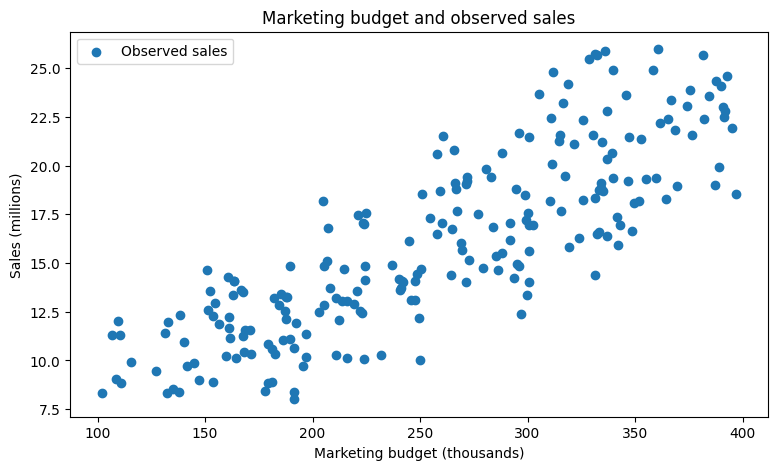

In [5]:
plt.figure(figsize=(9, 5))
plt.scatter(X[:, 0], y, color="tab:blue", label="Observed sales")
plt.xlabel("Marketing budget (thousands)")
plt.ylabel("Sales (millions)")
plt.title("Marketing budget and observed sales")
plt.legend()
plt.show()

## 3. Keep observations aside for evaluation

We train on 70% of the observations and test on the remaining 30%. The test set
lets us evaluate predictions for observations the model did not learn from.
`random_state=42` makes this random split repeatable; it is not a model parameter.

This split gives 155 training observations and 67 test observations. Both the
linear model and the baseline will use exactly the same split.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
print(f"Training observations: {len(X_train)}")
print(f"Test observations: {len(X_test)}")

Training observations: 155
Test observations: 67


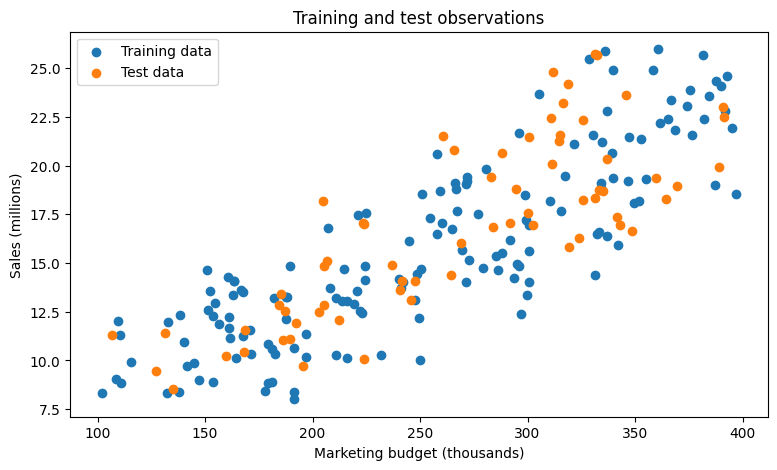

In [7]:
plt.figure(figsize=(9, 5))
plt.scatter(X_train[:, 0], y_train, color="tab:blue", label="Training data")
plt.scatter(X_test[:, 0], y_test, color="tab:orange", label="Test data")
plt.xlabel("Marketing budget (thousands)")
plt.ylabel("Sales (millions)")
plt.title("Training and test observations")
plt.legend()
plt.show()

## 4. Fit the straight line

`LinearRegression()` creates the estimator. `fit(X_train, y_train)` learns
$b_0$ and $b_1$ by minimizing the sum of squared training residuals:

$$\sum_i (y_i - \hat{y}_i)^2.$$

A residual is the difference between an observed value and its prediction. In a
scatter plot, it is the vertical distance from a dot to the model's line.
Squaring residuals makes larger errors contribute more to the fitting objective.

We also fit a mean baseline. `DummyRegressor(strategy="mean")` always predicts
the average training sales, regardless of budget. Comparing against it helps us
check whether using marketing budget improves predictions.

In [8]:
lr = LinearRegression()
lr.fit(X_train, y_train)

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'mean'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None


In [9]:
intercept = lr.intercept_
slope = lr.coef_[0]
print(f"Predicted sales (millions) = {intercept:.4f} + {slope:.5f} × budget (thousands)")
print(f"Baseline prediction: {baseline.constant_[0, 0]:.3f} million for every budget")

Predicted sales (millions) = 3.2949 + 0.04908 × budget (thousands)
Baseline prediction: 15.738 million for every budget


The learned equation is approximately

$$\hat{y} = 3.2949 + 0.04908x.$$

The slope means that an increase of **one thousand** in marketing budget is
associated with an increase of about **0.049 million** in predicted sales in
this fitted model. The intercept is where the fitted line crosses the sales axis.
Zero budget is outside the observed budget range, so the intercept does not
establish what actual sales would be without marketing.

These are associations learned from this practice dataset; they do not establish
that increasing budget causes the predicted sales increase.

## 5. Evaluate predictions

`predict(X_test)` applies the learned equation to held-out budgets. We report
two measures of performance:

- **Mean absolute error (MAE):** the average absolute difference between observed
  and predicted sales. It uses the target's units, millions; lower is better.
- **$R^2$:** compares squared prediction errors with the squared errors of always
  predicting the mean sales in the evaluated set. A score of 1 is a perfect fit,
  0 matches that benchmark, and negative values are worse than that benchmark.

The fitting objective uses squared errors, while MAE describes the average size
of the mistakes in a unit that is easy to interpret.

In [10]:
prediction = lr.predict(X_test)
prediction_train = lr.predict(X_train)
baseline_prediction = baseline.predict(X_test)
baseline_prediction_train = baseline.predict(X_train)

results = pd.DataFrame(
    {
        "Train MAE (millions)": [
            mean_absolute_error(y_train, baseline_prediction_train),
            mean_absolute_error(y_train, prediction_train),
        ],
        "Test MAE (millions)": [
            mean_absolute_error(y_test, baseline_prediction),
            mean_absolute_error(y_test, prediction),
        ],
        "Test R²": [
            r2_score(y_test, baseline_prediction),
            r2_score(y_test, prediction),
        ],
    },
    index=["Training-mean baseline", "Linear regression"],
)
results.round(3)

,Train MAE (millions),Test MAE (millions),Test R²
Training-mean baseline,3.920,3.893,-0.066
Linear regression,2.037,2.142,0.638


On this fixed split, linear regression has a training MAE of about **2.037 million**
and a test MAE of about **2.142 million**. Across the 67 test observations, its
predictions differ from observed sales by about 2.14 million on average. The mean
baseline has a test MAE of about **3.893 million**, so budget helps the model
make better predictions on this test set.

The test $R^2$ is about **0.638**: the model's squared prediction error is about
63.8% lower than the evaluated-set-mean benchmark used in the $R^2$ calculation.
The baseline's test $R^2$ is slightly negative because it predicts the **training**
mean, which differs from the **test** mean used by that calculation.

Training and test MAE are similar on this split. A single split is still only one
estimate of performance; more data or cross-validation within the training set
would help assess how stable the result is.

## 6. See the fitted line and its errors

We make a sorted grid of budgets to draw the regression line from left to right.
The line represents predicted sales; the dots represent actual observations.
The horizontal baseline predicts the same sales for every budget.

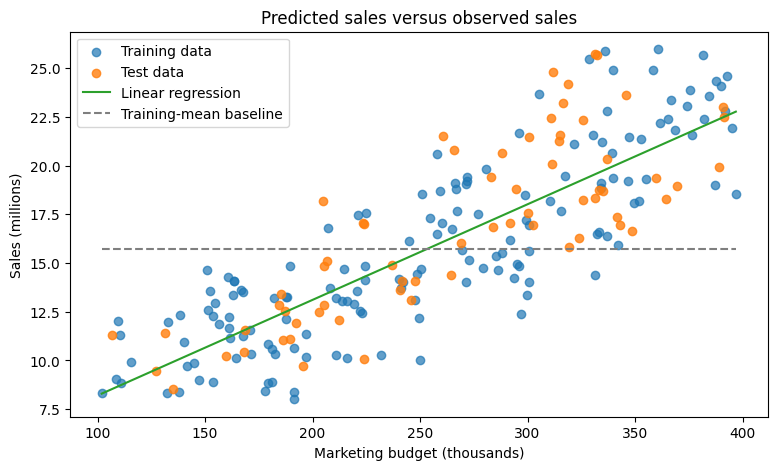

In [11]:
budget_grid = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
regression_line = lr.predict(budget_grid)
baseline_line = baseline.predict(budget_grid)

plt.figure(figsize=(9, 5))
plt.scatter(X_train[:, 0], y_train, color="tab:blue", label="Training data", alpha=0.7)
plt.scatter(X_test[:, 0], y_test, color="tab:orange", label="Test data", alpha=0.8)
plt.plot(budget_grid[:, 0], regression_line, color="tab:green", label="Linear regression")
plt.plot(budget_grid[:, 0], baseline_line, color="tab:gray", linestyle="--", label="Training-mean baseline")
plt.xlabel("Marketing budget (thousands)")
plt.ylabel("Sales (millions)")
plt.title("Predicted sales versus observed sales")
plt.legend()
plt.show()

The next plot shows **test residuals = observed sales - predicted sales**.
Positive residuals mean the model predicted too little; negative residuals mean
it predicted too much. A perfect prediction lies on the zero line. Look for
patterns, such as a curve or increasing spread, that the model may be missing.

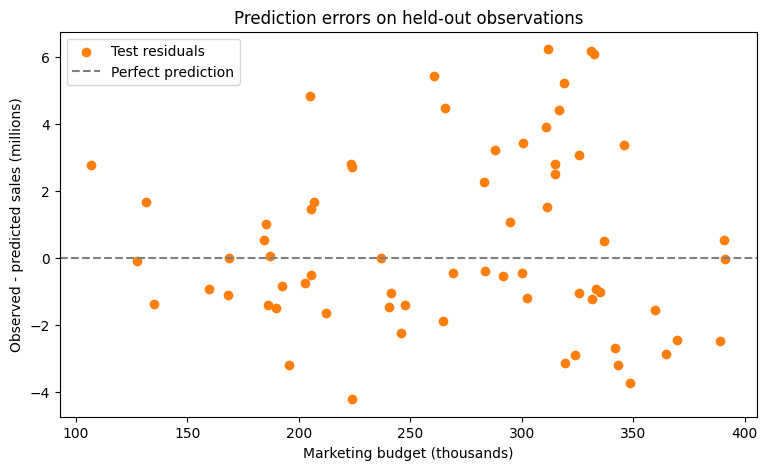

In [12]:
test_residuals = y_test - prediction

plt.figure(figsize=(9, 5))
plt.scatter(X_test[:, 0], test_residuals, color="tab:orange", label="Test residuals")
plt.axhline(0, color="tab:gray", linestyle="--", label="Perfect prediction")
plt.xlabel("Marketing budget (thousands)")
plt.ylabel("Observed - predicted sales (millions)")
plt.title("Prediction errors on held-out observations")
plt.legend()
plt.show()

## 7. Predict sales for a new budget

`[[215.0]]` represents one observation with one feature: a budget of **215 thousand**.
The outer brackets represent the observations; the inner brackets contain the
features for one observation. This preserves the two-dimensional shape expected
by `predict`.

The model predicts about **13.85 million** in sales for this budget. This is a
point estimate, and actual sales can differ, as the test errors show. The budget
is within the observed range of approximately 101.91 to 396.88 thousand.
Predictions outside the observed range would require further validation.

In [13]:
new_budget = np.array([[215.0]])
predicted_sales = lr.predict(new_budget)[0]
print(f"Predicted sales for a budget of {new_budget[0, 0]:.0f} thousand: {predicted_sales:.2f} million")

Predicted sales for a budget of 215 thousand: 13.85 million


## Continue to polynomial regression

A straight line predicts the same change in sales for each additional unit of
budget. The next notebook adds squared input features to learn a curved
relationship on a different dataset. Its error values use different target units,
so compare models within each dataset rather than comparing their MAEs directly.

Further reading: [scikit-learn LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
and [R² score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html).